In [1]:
# SRS: Income vs Age
import pandas as pd
import os
import numpy as np
import statsmodels.api as sm

folder = "acs_2024_1yr_csv"

files = [
    "csv_pus__psam_pusa.csv",
    "csv_pus__psam_pusb.csv",
    "csv_ppr__psam_p72.csv"
]

cols = [
    "PINCP", "AGEP", "PWGTP", "SCHL",
    "SEX", "RAC1P", "MAR", "WKHP",
    "STATE"
]

dfs = []

for f in files:
    path = os.path.join(folder, f)
    part = pd.read_csv(path, usecols=cols, low_memory=False)
    dfs.append(part)

df = pd.concat(dfs, ignore_index=True)

df[cols] = df[cols].apply(pd.to_numeric, errors="coerce")

# For this model, only clean variables actually used
df = df.dropna(subset=["PINCP", "AGEP", "PWGTP"])
df = df[np.isfinite(df[["PINCP", "AGEP", "PWGTP"]]).all(axis=1)]
df = df[df["PWGTP"] > 0].copy()

X = sm.add_constant(df["AGEP"])
y = df["PINCP"]

model = sm.WLS(y, X, weights=df["PWGTP"]).fit()

print(model.summary())

                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.013
Model:                            WLS   Adj. R-squared:                  0.013
Method:                 Least Squares   F-statistic:                 3.929e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:31:40   Log-Likelihood:            -3.7669e+07
No. Observations:             2936208   AIC:                         7.534e+07
Df Residuals:                 2936206   BIC:                         7.534e+07
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.252e+04    116.170    279.909      0.0

PINCP=32520+454.28*age
the predicted income when age=0 is about $32,520. But this is usually not substantively meaningful, because age 0 is outside the relevant working-age context.

The estimated slope coefficient on age is 454.28, meaning that each additional year of age is associated with about $454 higher annual income on average.

This means age alone explains only about 1.3% of the variation in income.

So age has a statistically significant relationship with income, but by itself it does not explain much of income differences.

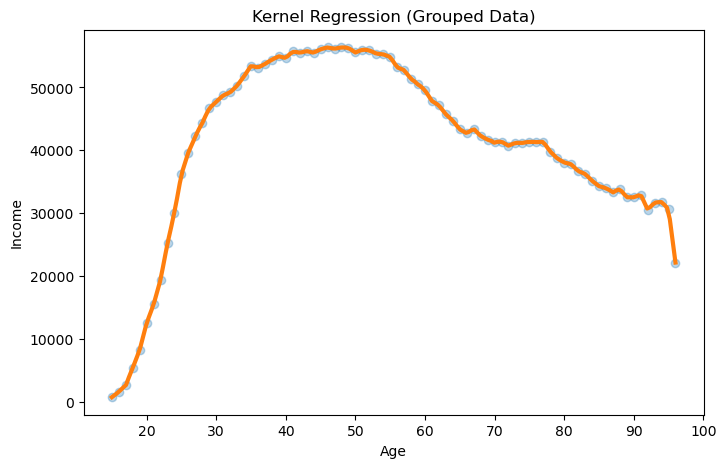

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

df_kr = df[["AGEP", "PINCP"]].dropna()
df_kr = df_kr[(df_kr["PINCP"] >= 0) & (df_kr["PINCP"] < 200000)]

df_grouped = df_kr.groupby("AGEP")["PINCP"].mean().reset_index()

x = df_grouped["AGEP"].values
y = df_grouped["PINCP"].values

# Now kernel is FAST
kr = sm.nonparametric.KernelReg(endog=y, exog=x, var_type='c')

x_grid = np.linspace(x.min(), x.max(), 200)
y_pred, _ = kr.fit(x_grid)

plt.figure(figsize=(8,5))
plt.plot(x, y, 'o', alpha=0.3)
plt.plot(x_grid, y_pred, linewidth=3)
plt.xlabel("Age")
plt.ylabel("Income")
plt.title("Kernel Regression (Grouped Data)")
plt.show()

In [3]:
#include age^2
df["age2"] = df["AGEP"] ** 2

X = df[["AGEP", "age2"]]
X = sm.add_constant(X)
y = df["PINCP"]

model2 = sm.WLS(y, X, weights=df["PWGTP"]).fit()

print(model2.summary())

                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.064
Model:                            WLS   Adj. R-squared:                  0.064
Method:                 Least Squares   F-statistic:                 9.956e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:31:46   Log-Likelihood:            -3.7592e+07
No. Observations:             2936208   AIC:                         7.518e+07
Df Residuals:                 2936205   BIC:                         7.519e+07
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -5.773e+04    253.870   -227.402      0.0

The negative coefficient on AGEP^2 indicates that income increases with age at a decreasing rate, and eventually begins to decline at older ages.It is concave. The marginal effect of age on income decreases as age increases.

age*=4864.0755/(2*45.1)=54 Predicted income increases with age up to about age 54, after which it begins to decline.

R^2 much higher, Adding the quadratic term substantially improves model fit, suggesting that the relationship between age and income is nonlinear.

The intercept is not economically meaningful in this context.

The large condition number suggests multicollinearity between age and age squared, which is expected in polynomial regressions but does not bias the estimates.

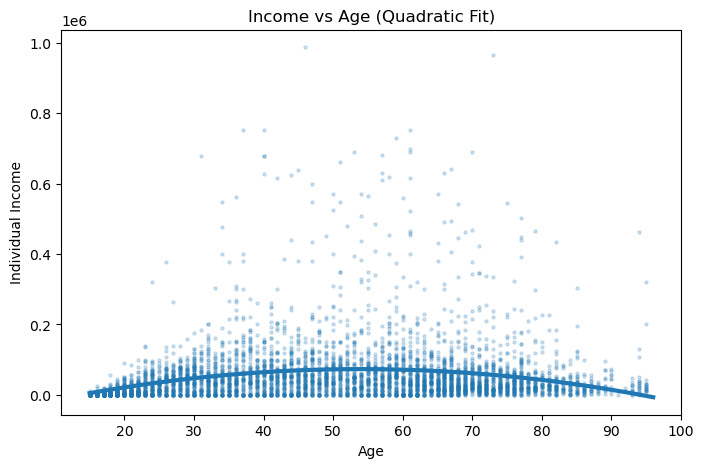

In [4]:
import matplotlib.pyplot as plt

# Sort data by age for smooth curve
df_plot = df.sort_values("AGEP")

# Predicted values from your quadratic model
X_plot = sm.add_constant(df_plot[["AGEP", "age2"]])
y_pred = model2.predict(X_plot)

# Plot
plt.figure(figsize=(8,5))

# Scatter (sample only to avoid clutter)
sample = df_plot.sample(5000, random_state=1)
plt.scatter(sample["AGEP"], sample["PINCP"], alpha=0.2, s=5)

# Fitted curve
plt.plot(df_plot["AGEP"], y_pred, linewidth=3)

plt.xlabel("Age")
plt.ylabel("Individual Income")
plt.title("Income vs Age (Quadratic Fit)")
plt.show()
# exclude some ages, some working hours(<20)

In [5]:
def edu_group(x):
    if 1 <= x <= 15:
        return "Less than high school"
    elif x in [16, 17]:
        return "High school or equivalent"
    elif 18 <= x <= 20:
        return "Some college or associate degree"
    elif x == 21:
        return "Bachelor's degree"
    elif 22 <= x <= 24:
        return "Graduate degree"
    else:
        return np.nan

df_edu = df.copy()

df_edu["edu_group"] = df_edu["SCHL"].apply(edu_group)

df_edu = df_edu.dropna(subset=["edu_group"]).copy()

In [6]:
for g, df_g in df_edu.groupby("edu_group"):
    df_g = df_g.copy()
    df_g["age2"] = df_g["AGEP"] ** 2

    X = sm.add_constant(df_g[["AGEP", "age2"]])
    y = df_g["PINCP"]

    model_g = sm.WLS(y, X, weights=df_g["PWGTP"]).fit()

    print(f"\n===== {g} =====")
    print(model_g.summary())


===== Bachelor's degree =====
                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.036
Model:                            WLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                 1.082e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:31:53   Log-Likelihood:            -7.5914e+06
No. Observations:              585502   AIC:                         1.518e+07
Df Residuals:                  585499   BIC:                         1.518e+07
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -5.994e+04


===== Some college or associate degree =====
                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.066
Model:                            WLS   Adj. R-squared:                  0.066
Method:                 Least Squares   F-statistic:                 2.823e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:31:55   Log-Likelihood:            -1.0026e+07
No. Observations:              805209   AIC:                         2.005e+07
Df Residuals:                  805206   BIC:                         2.005e+07
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const 

Income follows an inverted U-shape for every education group since age>0, age^2<0.

Higher education is associated with a much steeper increase in income with age.(coefficient)

Higher education groups have stronger curvature, meaning income rises faster but also declines more sharply at older ages.(age^2)

Peak income occurs around the mid-50s for all education groups, with only small differences across groups.

At any given age, individuals with higher education have substantially higher predicted income.

Age explains more variation in income for lower education groups, while income for highly educated individuals depends more on other factors.

The R² decreases when running regressions within education groups because the variation in income across education levels is removed. In the pooled model, both age and education contribute to explaining income variation, while within-group regressions rely only on age. As a result, the model explains a smaller share of the remaining variation.

In [7]:
'''from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import numpy as np
import statsmodels.formula.api as smf

data = df_edu.copy()

kf = KFold(n_splits=5, shuffle=True, random_state=1)

models = {
    "quadratic": "PINCP ~ AGEP + I(AGEP**2)",
    "edu": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group)",
    "age_interaction": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + AGEP:C(edu_group)",
    "full_interaction": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + AGEP:C(edu_group) + I(AGEP**2):C(edu_group)"
}

results = {}

for name, formula in models.items():
    mse_list = []

    for train_idx, test_idx in kf.split(data):
        train = data.iloc[train_idx]
        test = data.iloc[test_idx]

        model = smf.ols(formula, data=train).fit()
        pred = model.predict(test)

        mse = mean_squared_error(test["PINCP"], pred)
        mse_list.append(mse)

    results[name] = np.mean(mse_list)

print(results)'''

'from sklearn.model_selection import KFold\nfrom sklearn.metrics import mean_squared_error\nimport numpy as np\nimport statsmodels.formula.api as smf\n\ndata = df_edu.copy()\n\nkf = KFold(n_splits=5, shuffle=True, random_state=1)\n\nmodels = {\n    "quadratic": "PINCP ~ AGEP + I(AGEP**2)",\n    "edu": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group)",\n    "age_interaction": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + AGEP:C(edu_group)",\n    "full_interaction": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + AGEP:C(edu_group) + I(AGEP**2):C(edu_group)"\n}\n\nresults = {}\n\nfor name, formula in models.items():\n    mse_list = []\n\n    for train_idx, test_idx in kf.split(data):\n        train = data.iloc[train_idx]\n        test = data.iloc[test_idx]\n\n        model = smf.ols(formula, data=train).fit()\n        pred = model.predict(test)\n\n        mse = mean_squared_error(test["PINCP"], pred)\n        mse_list.append(mse)\n\n    results[name] = np.mean(mse_list)\n\nprint(results)'

model 1: age, age^2 model 2: age, age^2, edu model 3: age, age^2, edu, age*edu model 4: age, age^2, edu, age*edu, age^2*edu

In [8]:
import statsmodels.formula.api as smf

model2 = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group)",
    data=df_edu,
    weights=df_edu["PWGTP"]
).fit()

print(model2.summary())

                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.174
Model:                            WLS   Adj. R-squared:                  0.174
Method:                 Least Squares   F-statistic:                 1.028e+05
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:32:43   Log-Likelihood:            -3.7409e+07
No. Observations:             2936208   AIC:                         7.482e+07
Df Residuals:                 2936201   BIC:                         7.482e+07
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------

In [9]:
model3 = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + AGEP:C(edu_group)",
    data=df_edu,
    weights=df_edu["PWGTP"]
).fit()

print(model3.summary())

                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.174
Model:                            WLS   Adj. R-squared:                  0.174
Method:                 Least Squares   F-statistic:                 6.196e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:33:33   Log-Likelihood:            -3.7408e+07
No. Observations:             2936208   AIC:                         7.482e+07
Df Residuals:                 2936197   BIC:                         7.482e+07
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

In [10]:
model4 = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + AGEP:C(edu_group) + I(AGEP**2):C(edu_group)",
    data=df_edu,
    weights=df_edu["PWGTP"]
).fit()

print(model4.summary())

                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.181
Model:                            WLS   Adj. R-squared:                  0.181
Method:                 Least Squares   F-statistic:                 4.628e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:34:24   Log-Likelihood:            -3.7396e+07
No. Observations:             2936208   AIC:                         7.479e+07
Df Residuals:                 2936193   BIC:                         7.479e+07
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                                                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------

The results show a strong positive association between education and income. Individuals with higher levels of education earn significantly more on average, and this relationship holds across all ages. While income follows a similar life-cycle pattern for all groups, higher education shifts the entire age–income profile upward. Model comparisons indicate that most of the variation across education groups is driven by differences in income levels rather than differences in growth rates over age.

In [11]:
import statsmodels.formula.api as smf

# Drop missing gender values just for this model
df_gender = df_edu.dropna(subset=["SEX"]).copy()

# Treat SEX as categorical
model_gender = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX)",
    data=df_gender,
    weights=df_gender["PWGTP"]
).fit()

print(model_gender.summary())

                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.201
Model:                            WLS   Adj. R-squared:                  0.201
Method:                 Least Squares   F-statistic:                 1.052e+05
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:35:29   Log-Likelihood:            -3.7360e+07
No. Observations:             2936208   AIC:                         7.472e+07
Df Residuals:                 2936200   BIC:                         7.472e+07
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------

The coefficient on the female indicator is −25,510, indicating that women earn approximately $25,510 less than men on average, holding age and education constant.

There is a substantial negative association between being female and income. There is a substantial negative association between being female and income.

In [12]:
'''from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import numpy as np
import statsmodels.formula.api as smf

data = df_edu.dropna(subset=["SEX"]).copy()

kf = KFold(n_splits=5, shuffle=True, random_state=1)

models = {
    "A_baseline": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group)",
    "B_add_gender": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX)",
    "C_gender_interaction": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX) + C(edu_group):C(SEX)"
}

results = {}

for name, formula in models.items():
    mse_list = []

    for train_idx, test_idx in kf.split(data):
        train = data.iloc[train_idx]
        test = data.iloc[test_idx]

        model = smf.ols(formula, data=train).fit()
        pred = model.predict(test)

        mse = mean_squared_error(test["PINCP"], pred)
        mse_list.append(mse)

    results[name] = np.mean(mse_list)

print(results)'''

'from sklearn.model_selection import KFold\nfrom sklearn.metrics import mean_squared_error\nimport numpy as np\nimport statsmodels.formula.api as smf\n\ndata = df_edu.dropna(subset=["SEX"]).copy()\n\nkf = KFold(n_splits=5, shuffle=True, random_state=1)\n\nmodels = {\n    "A_baseline": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group)",\n    "B_add_gender": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX)",\n    "C_gender_interaction": "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX) + C(edu_group):C(SEX)"\n}\n\nresults = {}\n\nfor name, formula in models.items():\n    mse_list = []\n\n    for train_idx, test_idx in kf.split(data):\n        train = data.iloc[train_idx]\n        test = data.iloc[test_idx]\n\n        model = smf.ols(formula, data=train).fit()\n        pred = model.predict(test)\n\n        mse = mean_squared_error(test["PINCP"], pred)\n        mse_list.append(mse)\n\n    results[name] = np.mean(mse_list)\n\nprint(results)'

In [13]:
df_gender = df_edu.dropna(subset=["SEX"]).copy()

model_A = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group)",
    data=df_gender,
    weights=df_gender["PWGTP"]
).fit()

print("===== Model A: Baseline =====")
print(model_A.summary())

===== Model A: Baseline =====
                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.174
Model:                            WLS   Adj. R-squared:                  0.174
Method:                 Least Squares   F-statistic:                 1.028e+05
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:36:16   Log-Likelihood:            -3.7409e+07
No. Observations:             2936208   AIC:                         7.482e+07
Df Residuals:                 2936201   BIC:                         7.482e+07
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

In [14]:
model_B = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX)",
    data=df_gender,
    weights=df_gender["PWGTP"]
).fit()

print("===== Model B: Add Gender =====")
print(model_B.summary())

===== Model B: Add Gender =====
                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.201
Model:                            WLS   Adj. R-squared:                  0.201
Method:                 Least Squares   F-statistic:                 1.052e+05
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:37:21   Log-Likelihood:            -3.7360e+07
No. Observations:             2936208   AIC:                         7.472e+07
Df Residuals:                 2936200   BIC:                         7.472e+07
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                       coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

In [15]:
model_C = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX) + C(edu_group):C(SEX)",
    data=df_gender,
    weights=df_gender["PWGTP"]
).fit()

print("===== Model C: Gender Interaction =====")
print(model_C.summary())

===== Model C: Gender Interaction =====
                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.209
Model:                            WLS   Adj. R-squared:                  0.209
Method:                 Least Squares   F-statistic:                 7.072e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:38:28   Log-Likelihood:            -3.7344e+07
No. Observations:             2936208   AIC:                         7.469e+07
Df Residuals:                 2936196   BIC:                         7.469e+07
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                                                   coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

Women earn less than men at all education levels. Women earn less than men at all education levels.

Baseline(Bachelor's): -38570
Graduate: -38k+(-16k)
High School: (-38k+23k)
<HS: -38k+29k
college: -38k+18k

In [16]:
import statsmodels.formula.api as smf

df_hours = df_gender.dropna(subset=["WKHP"]).copy()

model_D = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX) + C(edu_group):C(SEX) + WKHP",
    data=df_hours,
    weights=df_hours["PWGTP"]
).fit()

print("===== Model D: Add WKHP =====")
print(model_D.summary())

===== Model D: Add WKHP =====
                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.246
Model:                            WLS   Adj. R-squared:                  0.246
Method:                 Least Squares   F-statistic:                 4.834e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:39:10   Log-Likelihood:            -2.2728e+07
No. Observations:             1776716   AIC:                         4.546e+07
Df Residuals:                 1776703   BIC:                         4.546e+07
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                                                   coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

Hours worked explains a large additional portion of income variation. Each additional hour worked per week is associated with about $1,435 higher annual income. 

Gender gap(Bachelor): 32260
Graduate: -32k-21k=-53k
HS: -32k+22k=-10k
<HS: -32k+29k=-3k
College: -32k+18k=-14k

In [35]:
df_race = df_hours.dropna(subset=["MAR"]).copy()
model_E = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX) + C(edu_group):C(SEX) + WKHP + C(RAC1P)",
    data=df_race,
    weights=df_race["PWGTP"]
).fit()

print("===== Model E: Add Race =====")
print(model_E.summary())

===== Primary Model + Marital Status =====
                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.251
Model:                            WLS   Adj. R-squared:                  0.251
Method:                 Least Squares   F-statistic:                 3.730e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:29:27   Log-Likelihood:            -2.2721e+07
No. Observations:             1776716   AIC:                         4.544e+07
Df Residuals:                 1776699   BIC:                         4.544e+07
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                                                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

After controlling for age, education, gender, and hours worked, most racial groups have lower average income than White individuals, while Asian individuals have slightly higher income.

In [34]:
df_mar = df_race.dropna(subset=["MAR"]).copy()
model_F = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX) + C(edu_group):C(SEX) + WKHP + C(RAC1P) + C(MAR)",
    data=df_mar,
    weights=df_mar["PWGTP"]
).fit()

print("===== Model F: Add Marital Status =====")
print(model_F.summary())

===== Model F: Add Marital Status =====
                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.251
Model:                            WLS   Adj. R-squared:                  0.251
Method:                 Least Squares   F-statistic:                 3.730e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:26:54   Log-Likelihood:            -2.2721e+07
No. Observations:             1776716   AIC:                         4.544e+07
Df Residuals:                 1776699   BIC:                         4.544e+07
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                                                   coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

Married individuals tend to have higher income, possibly due to Married individuals tend to have higher income, dual income households, age/life stage

Adding marital status barely changes the gender gap. Adding marital status barely changes the gender gap

In [19]:
df_final = df_gender.dropna(subset=["WKHP"]).copy()

# Final chosen linear model
model_final = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX) + C(edu_group):C(SEX) + WKHP",
    data=df_final,
    weights=df_final["PWGTP"]
).fit()

print("===== Final Linear Model (Model D) =====")
print(model_final.summary())

===== Final Linear Model (Model D) =====
                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.246
Model:                            WLS   Adj. R-squared:                  0.246
Method:                 Least Squares   F-statistic:                 4.834e+04
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:41:52   Log-Likelihood:            -2.2728e+07
No. Observations:             1776716   AIC:                         4.546e+07
Df Residuals:                 1776703   BIC:                         4.546e+07
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                                                   coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------

In [20]:
# Adjusted predictions with 95% confidence intervals
# Hold age and weekly work hours at their weighted means

age_mean = np.average(df_final["AGEP"], weights=df_final["PWGTP"])
hours_mean = np.average(df_final["WKHP"], weights=df_final["PWGTP"])

edu_order = [
    "Less than high school",
    "High school or equivalent",
    "Some college or associate degree",
    "Bachelor's degree",
    "Graduate degree"
]

pred_rows = []

for sex in [1, 2]:
    for edu in edu_order:
        pred_rows.append({
            "AGEP": age_mean,
            "edu_group": edu,
            "SEX": sex,
            "WKHP": hours_mean
        })

pred_df = pd.DataFrame(pred_rows)

prediction = model_final.get_prediction(pred_df).summary_frame(alpha=0.05)

pred_df["predicted_income"] = prediction["mean"].values
pred_df["ci_lower"] = prediction["mean_ci_lower"].values
pred_df["ci_upper"] = prediction["mean_ci_upper"].values
pred_df["Gender"] = pred_df["SEX"].map({1: "Men", 2: "Women"})

print(pred_df[
    ["edu_group", "Gender",
     "predicted_income", "ci_lower", "ci_upper"]
].to_string(index=False))

                       edu_group Gender  predicted_income      ci_lower      ci_upper
           Less than high school    Men      47393.726399  46906.113146  47881.339653
       High school or equivalent    Men      53443.462818  53126.092354  53760.833283
Some college or associate degree    Men      65247.185502  64933.736418  65560.634587
               Bachelor's degree    Men     107219.666580 106879.516087 107559.817074
                 Graduate degree    Men     152925.363278 152487.839000 153362.887557
           Less than high school  Women      44070.787463  43472.247486  44669.327440
       High school or equivalent  Women      43920.419462  43551.920434  44288.918490
Some college or associate degree  Women      51107.977678  50795.778465  51420.176890
               Bachelor's degree  Women      74960.207234  74630.765413  75289.649056
                 Graduate degree  Women      99333.018998  98934.292356  99731.745641


In [21]:
from sklearn.metrics import mean_squared_error

state_results = []

formula = (
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + "
    "C(SEX) + C(edu_group):C(SEX) + WKHP"
)

for state, df_state in df_mar.groupby("STATE"):
    df_state = df_state.copy()
    
    if len(df_state) < 100:
        continue

    model_state = smf.wls(
        formula,
        data=df_state,
        weights=df_state["PWGTP"]
    ).fit()

    pred_state = model_state.predict(df_state)
    mse_state = mean_squared_error(df_state["PINCP"], pred_state)

    state_results.append({
        "STATE": state,
        "n": len(df_state),
        "R2": model_state.rsquared,
        "Adj_R2": model_state.rsquared_adj,
        "MSE": mse_state
    })

state_fit = pd.DataFrame(state_results)

print("===== Best fit states by R² =====")
print(state_fit.sort_values("R2", ascending=False).head(10))

print("\n===== Worst fit states by R² =====")
print(state_fit.sort_values("R2", ascending=True).head(10))

print("\n===== Best fit states by MSE =====")
print(state_fit.sort_values("MSE", ascending=True).head(10))

print("\n===== Worst fit states by MSE =====")
print(state_fit.sort_values("MSE", ascending=False).head(10))

===== Best fit states by R² =====
    STATE      n        R2    Adj_R2           MSE
46     51  47895  0.283293  0.283114  6.367647e+09
0       1  24865  0.282086  0.281740  3.479503e+09
7      10   4950  0.280878  0.279130  5.149902e+09
35     39  63724  0.276458  0.276321  3.896615e+09
20     24  34721  0.273871  0.273620  7.056741e+09
15     19  18064  0.273645  0.273162  2.482930e+09
44     49  19756  0.272913  0.272471  5.203699e+09
39     44   5655  0.272773  0.271226  4.585654e+09
12     16  10589  0.272179  0.271354  3.707258e+09
23     27  32437  0.266613  0.266342  4.402644e+09

===== Worst fit states by R² =====
    STATE       n        R2    Adj_R2           MSE
34     38    4594  0.178861  0.176710  5.195771e+09
26     30    5921  0.181402  0.179740  3.976047e+09
11     15    8034  0.206654  0.205467  5.269091e+09
28     32   16392  0.206950  0.206369  5.958699e+09
50     56    3258  0.207642  0.204712  3.858898e+09
51     72    9584  0.213276  0.212290  1.733889e+09
9    

The model fits some states better than others, indicating regional differences in income determination

In [22]:
import statsmodels.formula.api as smf

model_state_gender = smf.wls(
    "PINCP ~ AGEP + I(AGEP**2) + C(edu_group) + C(SEX) + C(edu_group):C(SEX) + WKHP + C(STATE) + C(STATE):C(SEX)",
    data=df_final,
    weights=df_final["PWGTP"]
).fit()

print(model_state_gender.summary())

                            WLS Regression Results                            
Dep. Variable:                  PINCP   R-squared:                       0.253
Model:                            WLS   Adj. R-squared:                  0.253
Method:                 Least Squares   F-statistic:                     5271.
Date:                Mon, 21 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:44:53   Log-Likelihood:            -2.2720e+07
No. Observations:             1776716   AIC:                         4.544e+07
Df Residuals:                 1776601   BIC:                         4.544e+07
Df Model:                         114                                         
Covariance Type:            nonrobust                                         
                                                                   coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------

In [23]:
gender_counts = (
    df_final.groupby(["STATE", "SEX"])
    .size()
    .unstack(fill_value=0)
)

print(gender_counts)

SEX         1      2
STATE               
1       12883  11982
2        1994   1555
4       19298  17329
5        7684   7229
6      107671  96948
8       18479  16693
9       10589  10309
10       2512   2438
11       2009   2266
12      53960  51213
13      29697  27964
15       4180   3854
16       5681   4908
17      35308  33144
18      19375  17744
19       9449   8615
20       8683   7655
21      12183  11076
22      10938  10571
23       3865   3681
24      17490  17231
25      21356  21596
26      26756  24277
27      17052  15385
28       6943   6923
29      16908  15893
30       3121   2800
31       5962   5218
32       8643   7749
33       4216   3900
34      26470  25055
35       4964   4614
36      54530  54051
37      30074  28350
38       2486   2108
39      32884  30840
40       9872   8849
41      11827  11123
42      36023  33597
44       2879   2776
45      14467  13884
46       2823   2448
47      19556  18379
48      78572  70611
49      10759   8997
50       1993

In [24]:
print(model_final.params.index)

Index(['Intercept', 'C(edu_group)[T.Graduate degree]',
       'C(edu_group)[T.High school or equivalent]',
       'C(edu_group)[T.Less than high school]',
       'C(edu_group)[T.Some college or associate degree]', 'C(SEX)[T.2]',
       'C(edu_group)[T.Graduate degree]:C(SEX)[T.2]',
       'C(edu_group)[T.High school or equivalent]:C(SEX)[T.2]',
       'C(edu_group)[T.Less than high school]:C(SEX)[T.2]',
       'C(edu_group)[T.Some college or associate degree]:C(SEX)[T.2]', 'AGEP',
       'I(AGEP ** 2)', 'WKHP'],
      dtype='str')


In [25]:
grad_men = model_final.params[
    "C(edu_group)[T.Graduate degree]"
]

grad_interaction = model_final.params[
    "C(edu_group)[T.Graduate degree]:C(SEX)[T.2]"
]

grad_women = grad_men + grad_interaction

print(f"Graduate degree vs Bachelor's degree - Men: ${grad_men:,.2f}")
print(f"Graduate degree vs Bachelor's degree - Women: ${grad_women:,.2f}")
print(f"Difference in graduate-degree association, Women - Men: ${grad_interaction:,.2f}")

Graduate degree vs Bachelor's degree - Men: $45,705.70
Graduate degree vs Bachelor's degree - Women: $24,372.81
Difference in graduate-degree association, Women - Men: $-21,332.88


In [26]:
bachelor_gap = model_final.params["C(SEX)[T.2]"]

graduate_gap = (
    model_final.params["C(SEX)[T.2]"]
    + model_final.params[
        "C(edu_group)[T.Graduate degree]:C(SEX)[T.2]"
    ]
)

print(f"Bachelor's degree, Women - Men: ${bachelor_gap:,.2f}")
print(f"Graduate degree, Women - Men: ${graduate_gap:,.2f}")

print(f"Bachelor's degree, Men - Women: ${-bachelor_gap:,.2f}")
print(f"Graduate degree, Men - Women: ${-graduate_gap:,.2f}")

Bachelor's degree, Women - Men: $-32,259.46
Graduate degree, Women - Men: $-53,592.34
Bachelor's degree, Men - Women: $32,259.46
Graduate degree, Men - Women: $53,592.34


In [27]:
# Mean values used for adjusted predictions
mean_age = np.average(
    df_hours["AGEP"],
    weights=df_hours["PWGTP"]
)

mean_hours = np.average(
    df_hours["WKHP"],
    weights=df_hours["PWGTP"]
)

print("Weighted mean age:", mean_age)
print("Weighted mean weekly hours:", mean_hours)

Weighted mean age: 41.89997053956788
Weighted mean weekly hours: 37.86658660767944


In [28]:
edu_dist = (
    df_final.groupby("edu_group")["PWGTP"]
    .sum()
    .sort_values(ascending=False)
)

edu_pct = 100 * edu_dist / edu_dist.sum()

print(edu_pct)

edu_group
Some college or associate degree    28.504371
High school or equivalent           24.192059
Bachelor's degree                   23.518328
Graduate degree                     14.649619
Less than high school                9.135623
Name: PWGTP, dtype: float64


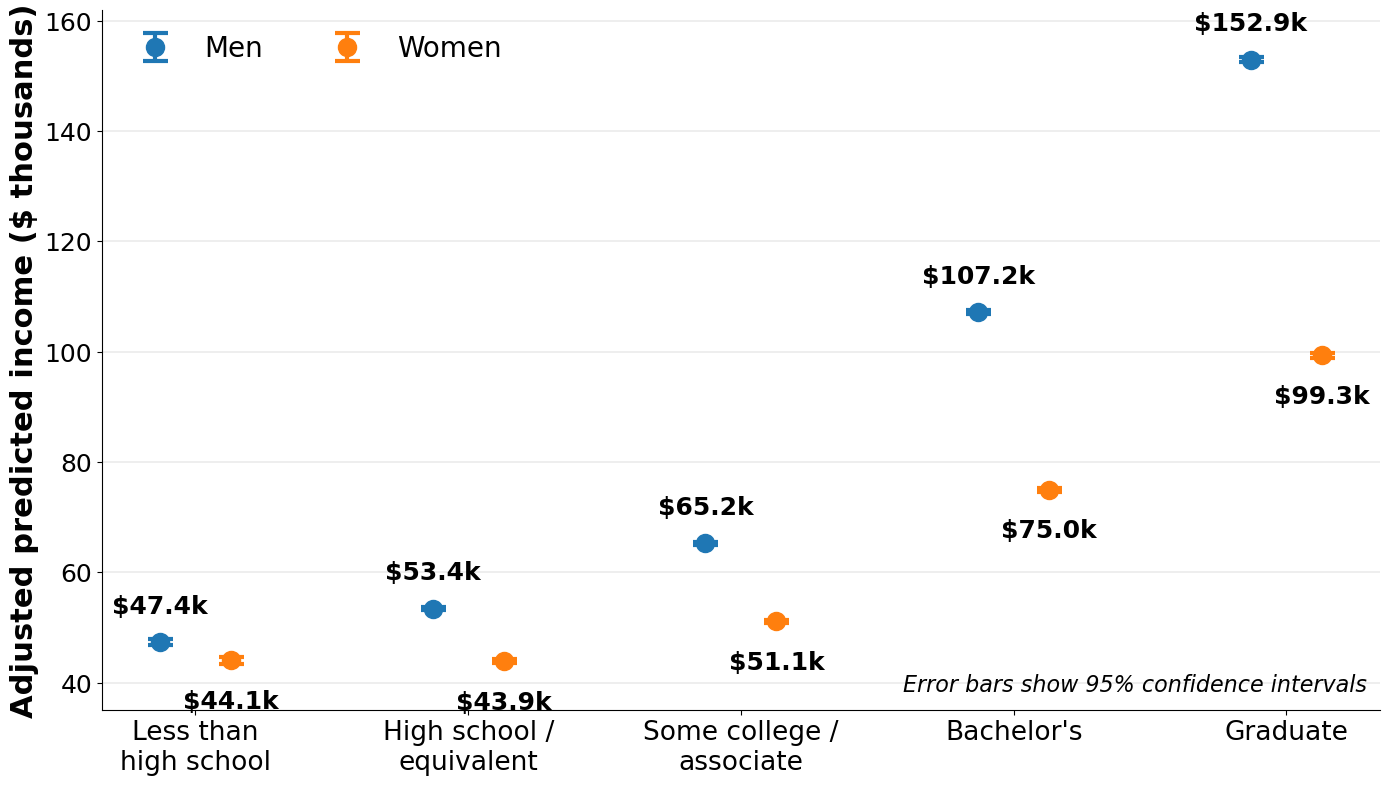

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Adjusted predictions + 95% confidence intervals
# ---------------------------------------------------------

age_mean = np.average(
    df_final["AGEP"],
    weights=df_final["PWGTP"]
)

hours_mean = np.average(
    df_final["WKHP"],
    weights=df_final["PWGTP"]
)

edu_order = [
    "Less than high school",
    "High school or equivalent",
    "Some college or associate degree",
    "Bachelor's degree",
    "Graduate degree"
]

short_labels = [
    "Less than\nhigh school",
    "High school /\nequivalent",
    "Some college /\nassociate",
    "Bachelor's",
    "Graduate"
]

pred_rows = []

for sex in [1, 2]:
    for edu in edu_order:
        pred_rows.append({
            "AGEP": age_mean,
            "edu_group": edu,
            "SEX": sex,
            "WKHP": hours_mean
        })

pred_df = pd.DataFrame(pred_rows)

prediction = model_final.get_prediction(
    pred_df
).summary_frame(alpha=0.05)

pred_df["predicted_income"] = prediction["mean"].values
pred_df["ci_lower"] = prediction["mean_ci_lower"].values
pred_df["ci_upper"] = prediction["mean_ci_upper"].values

# Separate men and women
men = pred_df[pred_df["SEX"] == 1].reset_index(drop=True)
women = pred_df[pred_df["SEX"] == 2].reset_index(drop=True)

x = np.arange(len(edu_order))
offset = 0.13


# ---------------------------------------------------------
# FIGURE
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 8))


# MEN
ax.errorbar(
    x - offset,
    men["predicted_income"] / 1000,

    yerr=[
        (men["predicted_income"] - men["ci_lower"]) / 1000,
        (men["ci_upper"] - men["predicted_income"]) / 1000
    ],

    fmt="o",
    markersize=13,
    capsize=9,
    capthick=3,
    elinewidth=3,
    label="Men",
    zorder=3
)


# WOMEN
ax.errorbar(
    x + offset,
    women["predicted_income"] / 1000,

    yerr=[
        (women["predicted_income"] - women["ci_lower"]) / 1000,
        (women["ci_upper"] - women["predicted_income"]) / 1000
    ],

    fmt="o",
    markersize=13,
    capsize=9,
    capthick=3,
    elinewidth=3,
    label="Women",
    zorder=3
)


# ---------------------------------------------------------
# VALUE LABELS
# ---------------------------------------------------------

for i in range(len(x)):

    ax.annotate(
        f"${men.loc[i, 'predicted_income']/1000:.1f}k",
        (
            x[i] - offset,
            men.loc[i, "predicted_income"] / 1000
        ),
        xytext=(0, 17),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=18,
        fontweight="bold"
    )

    ax.annotate(
        f"${women.loc[i, 'predicted_income']/1000:.1f}k",
        (
            x[i] + offset,
            women.loc[i, "predicted_income"] / 1000
        ),
        xytext=(0, -21),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=18,
        fontweight="bold"
    )


# ---------------------------------------------------------
# FORMATTING
# ---------------------------------------------------------

ax.set_xticks(x)

ax.set_xticklabels(
    short_labels,
    fontsize=19
)

ax.set_ylabel(
    "Adjusted predicted income ($ thousands)",
    fontsize=22,
    fontweight="bold"
)

ax.tick_params(
    axis="y",
    labelsize=18
)

ax.set_ylim(35, 162)

ax.legend(
    fontsize=20,
    frameon=False,
    ncol=2,
    loc="upper left"
)

ax.grid(
    axis="y",
    alpha=0.25,
    linewidth=1.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Explain what the error bars represent
ax.text(
    0.99,
    0.02,
    "Error bars show 95% confidence intervals",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=16,
    style="italic"
)

plt.tight_layout()


# ---------------------------------------------------------
# SAVE
# ---------------------------------------------------------

plt.savefig(
    "predicted_income_education_gender_95CI.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
# ============================================================
# Key education × gender contrasts with 95% confidence intervals
# ============================================================

import numpy as np
import pandas as pd

# See the exact coefficient names in the fitted model
print(model_final.params.index.tolist())

['Intercept', 'C(edu_group)[T.Graduate degree]', 'C(edu_group)[T.High school or equivalent]', 'C(edu_group)[T.Less than high school]', 'C(edu_group)[T.Some college or associate degree]', 'C(SEX)[T.2]', 'C(edu_group)[T.Graduate degree]:C(SEX)[T.2]', 'C(edu_group)[T.High school or equivalent]:C(SEX)[T.2]', 'C(edu_group)[T.Less than high school]:C(SEX)[T.2]', 'C(edu_group)[T.Some college or associate degree]:C(SEX)[T.2]', 'AGEP', 'I(AGEP ** 2)', 'WKHP']


                         Contrast      Estimate         Lower         Upper
0    Graduate vs. Bachelor's\nMen  45705.696698  45173.017161  46238.376236
1  Graduate vs. Bachelor's\nWomen  24372.811764  23868.763735  24876.859793
2       Men vs. Women\nBachelor's  32259.459346  31805.227280  32713.691411
3         Men vs. Women\nGraduate  53592.344280  53015.628977  54169.059583


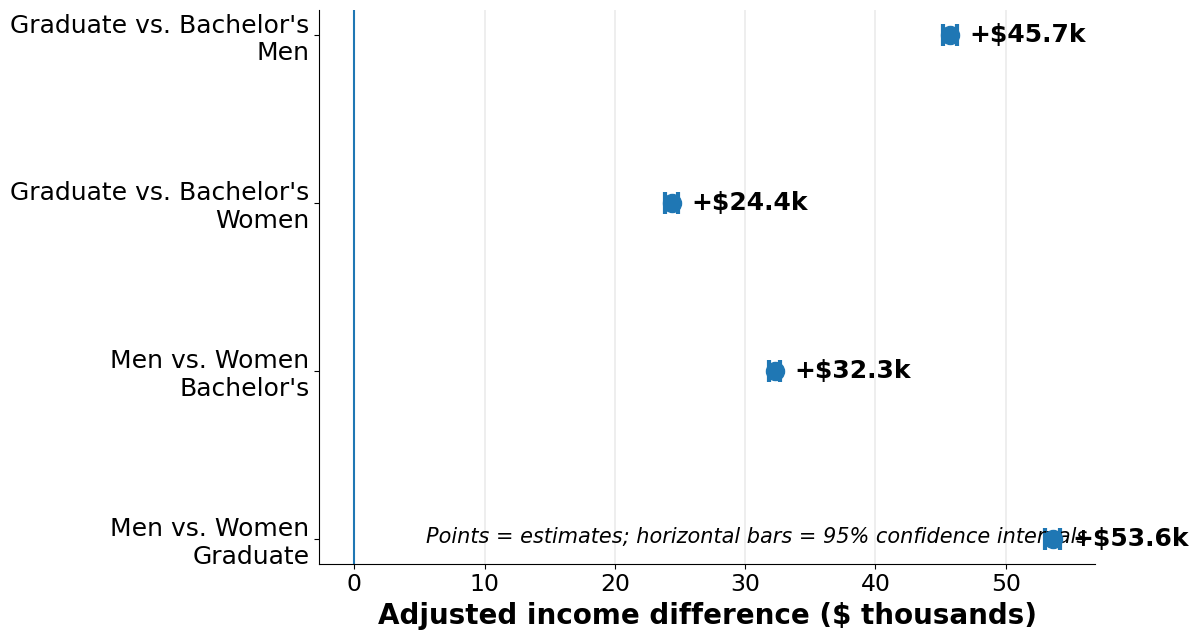

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Coefficient names
# ============================================================

names = list(model_final.params.index)
p = len(names)

def contrast_vector(weights):
    """
    weights = dictionary:
    {coefficient_name: multiplier}
    """
    c = np.zeros(p)

    for name, weight in weights.items():
        c[names.index(name)] = weight

    return c


# ============================================================
# Useful coefficient names
# ============================================================

grad = "C(edu_group)[T.Graduate degree]"
female = "C(SEX)[T.2]"
grad_female = (
    "C(edu_group)[T.Graduate degree]:C(SEX)[T.2]"
)


# Bachelor's is the reference education category.
# SEX=1 (Men) is the reference gender category.


# ============================================================
# Define four contrasts
# ============================================================

contrasts = {

    # Graduate - Bachelor's among men
    "Graduate vs. Bachelor's\nMen":
        contrast_vector({
            grad: 1
        }),

    # Graduate - Bachelor's among women
    # = graduate main effect + graduate×female interaction
    "Graduate vs. Bachelor's\nWomen":
        contrast_vector({
            grad: 1,
            grad_female: 1
        }),

    # Men - Women among Bachelor's
    # female coefficient is Women - Men,
    # so multiply by -1
    "Men vs. Women\nBachelor's":
        contrast_vector({
            female: -1
        }),

    # Men - Women among Graduate
    # Women-Men at graduate =
    # female + graduate×female
    # so Men-Women is the negative of both
    "Men vs. Women\nGraduate":
        contrast_vector({
            female: -1,
            grad_female: -1
        })
}


# ============================================================
# Calculate estimates and 95% confidence intervals
# ============================================================

results = []

for label, c in contrasts.items():

    test = model_final.t_test(c)

    estimate = float(np.asarray(test.effect).squeeze())
    ci = np.asarray(test.conf_int(alpha=0.05)).squeeze()

    lower = float(ci[0])
    upper = float(ci[1])

    results.append({
        "Contrast": label,
        "Estimate": estimate,
        "Lower": lower,
        "Upper": upper
    })


contrast_df = pd.DataFrame(results)

print(contrast_df)


# ============================================================
# Convert to $ thousands
# ============================================================

contrast_df["Estimate_k"] = contrast_df["Estimate"] / 1000
contrast_df["Lower_k"] = contrast_df["Lower"] / 1000
contrast_df["Upper_k"] = contrast_df["Upper"] / 1000


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6.5))

y = np.arange(len(contrast_df))[::-1]

x = contrast_df["Estimate_k"].values

xerr_lower = (
    contrast_df["Estimate_k"] -
    contrast_df["Lower_k"]
).values

xerr_upper = (
    contrast_df["Upper_k"] -
    contrast_df["Estimate_k"]
).values


ax.errorbar(
    x,
    y,
    xerr=[xerr_lower, xerr_upper],
    fmt="o",
    markersize=13,
    capsize=8,
    capthick=3,
    elinewidth=3,
    zorder=3
)


# ============================================================
# Labels
# ============================================================

for xi, yi in zip(x, y):

    ax.annotate(
        f"+${xi:.1f}k",
        (xi, yi),
        xytext=(14, 0),
        textcoords="offset points",
        va="center",
        fontsize=18,
        fontweight="bold"
    )


ax.set_yticks(y)

ax.set_yticklabels(
    contrast_df["Contrast"],
    fontsize=18
)

ax.set_xlabel(
    "Adjusted income difference ($ thousands)",
    fontsize=20,
    fontweight="bold"
)

ax.tick_params(
    axis="x",
    labelsize=17
)

ax.axvline(
    0,
    linewidth=1.5
)

ax.grid(
    axis="x",
    alpha=0.25,
    linewidth=1.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ============================================================
# CI note
# ============================================================

ax.text(
    0.99,
    0.03,
    "Points = estimates; horizontal bars = 95% confidence intervals",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=15,
    style="italic"
)


plt.tight_layout()

plt.savefig(
    "education_gender_contrasts_95CI.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
print(
    contrast_df[
        ["Contrast", "Estimate_k", "Lower_k", "Upper_k"]
    ].to_string(index=False)
)

                      Contrast  Estimate_k   Lower_k   Upper_k
  Graduate vs. Bachelor's\nMen   45.705697 45.173017 46.238376
Graduate vs. Bachelor's\nWomen   24.372812 23.868764 24.876860
     Men vs. Women\nBachelor's   32.259459 31.805227 32.713691
       Men vs. Women\nGraduate   53.592344 53.015629 54.169060


In [33]:
\vspace{0.12cm}

{\fontsize{23}{29}\selectfont
\textbf{Key Adjusted Contrasts with 95\% Confidence Intervals}
}

\vspace{0.10cm}

\begin{center}

{\fontsize{20}{26}\selectfont
\renewcommand{\arraystretch}{1.35}

\begin{tabular}{
>{\raggedright\arraybackslash}p{0.48\linewidth}
>{\raggedleft\arraybackslash}p{0.18\linewidth}
>{\raggedleft\arraybackslash}p{0.25\linewidth}
}

\toprule
\textbf{Contrast} &
\textbf{Difference} &
\textbf{95\% CI} \\

\midrule

Graduate vs.\ Bachelor's, Men
& \$45.7k
& [\$45.2k, \$46.2k] \\

Graduate vs.\ Bachelor's, Women
& \$24.4k
& [\$23.9k, \$24.9k] \\

Men vs.\ Women, Bachelor's
& \$32.3k
& [\$31.8k, \$32.7k] \\

Men vs.\ Women, Graduate
& \$53.6k
& [\$53.0k, \$54.2k] \\

\bottomrule

\end{tabular}
}

\end{center}

SyntaxError: unexpected character after line continuation character (400463807.py, line 1)